In [6]:

from sklearn.datasets import load_iris

iris = load_iris()

print("Dataset loaded successfully!")
print("Number of flowers:", len(iris.data))
print("Features:", iris.feature_names)
print("Flower types:", iris.target_names)


Dataset loaded successfully!
Number of flowers: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Flower types: ['setosa' 'versicolor' 'virginica']


In [7]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# Prepare input features and target labels
X = iris.data
y = iris.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train the model
model = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Check performance
print("Model trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))


Model trained successfully!
Training samples: 120
Testing samples: 30
Model Accuracy: 96.67 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



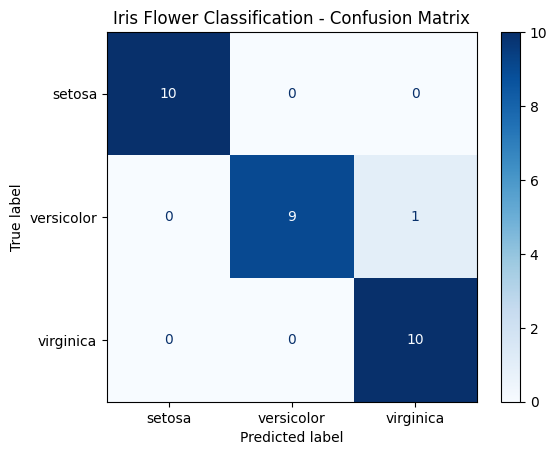

In [8]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Display the model's predictions
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Iris Flower Classification - Confusion Matrix")
plt.show()
